In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [27]:
DATA_PATH = Path("../data/processed/train.csv")

In [28]:
df = pd.read_csv(DATA_PATH)

In [29]:
df.head()

,vehicle_speed,leader_speed,leader_distance,relative_speed,time_to_collision,speed_limit,target_speed
0,8.84,14.30,36.94,-5.46,99.00,13.89,10.21
1,21.66,17.88,6.73,3.78,1.78,22.22,0.32
2,4.33,11.75,50.30,-7.42,99.00,22.22,6.62
3,11.16,3.44,66.15,7.71,8.57,22.22,14.49
4,5.86,1.95,38.95,3.91,9.96,13.89,4.36


In [30]:
df.shape

(40000, 7)

In [31]:
print(df.isnull().sum())
print(df.dtypes)
df.describe().T

vehicle_speed        0
leader_speed         0
leader_distance      0
relative_speed       0
time_to_collision    0
speed_limit          0
target_speed         0
dtype: int64
vehicle_speed        float64
leader_speed         float64
leader_distance      float64
relative_speed       float64
time_to_collision    float64
speed_limit          float64
target_speed         float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
vehicle_speed,40000.0,7.477896,5.459366,0.00,3.18,6.37,10.8200,23.15
leader_speed,40000.0,7.427696,5.407301,0.00,3.20,6.32,10.6925,24.07
leader_distance,40000.0,40.794403,22.537164,0.50,21.29,40.61,60.2600,82.83
relative_speed,40000.0,0.050168,6.551625,-22.75,-3.83,0.06,3.9000,22.45
time_to_collision,40000.0,59.299779,43.596792,0.10,9.31,99.00,99.0000,99.00
speed_limit,40000.0,14.881583,5.709192,8.33,8.33,13.89,22.2200,22.22
target_speed,40000.0,6.582556,5.168923,0.00,2.80,5.57,8.8200,22.22


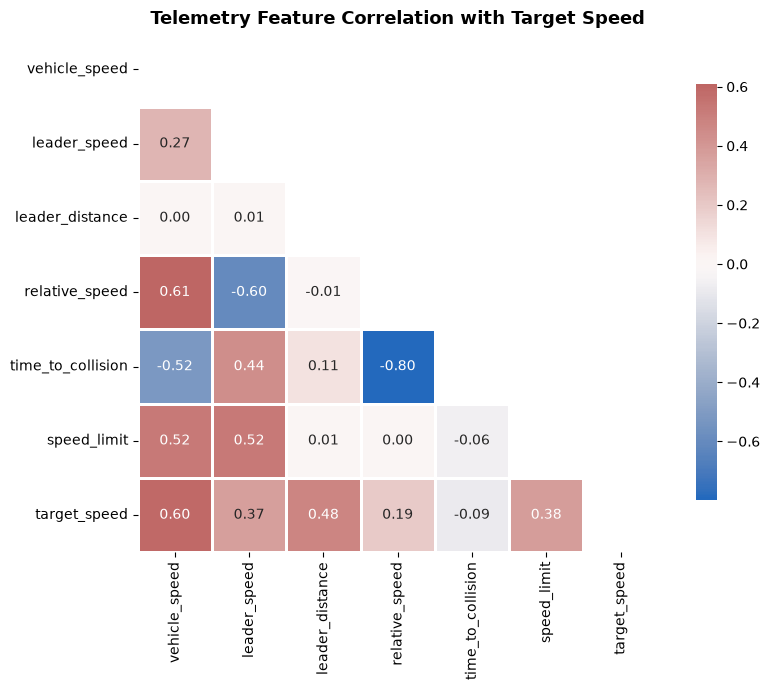

In [32]:
plt.figure(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap="vlag", 
    center=0,
    square=True, 
    linewidths=0.8,
    cbar_kws={"shrink": 0.8}
)
plt.title("Telemetry Feature Correlation with Target Speed", fontsize=13, weight="bold")
plt.tight_layout()
plt.show()

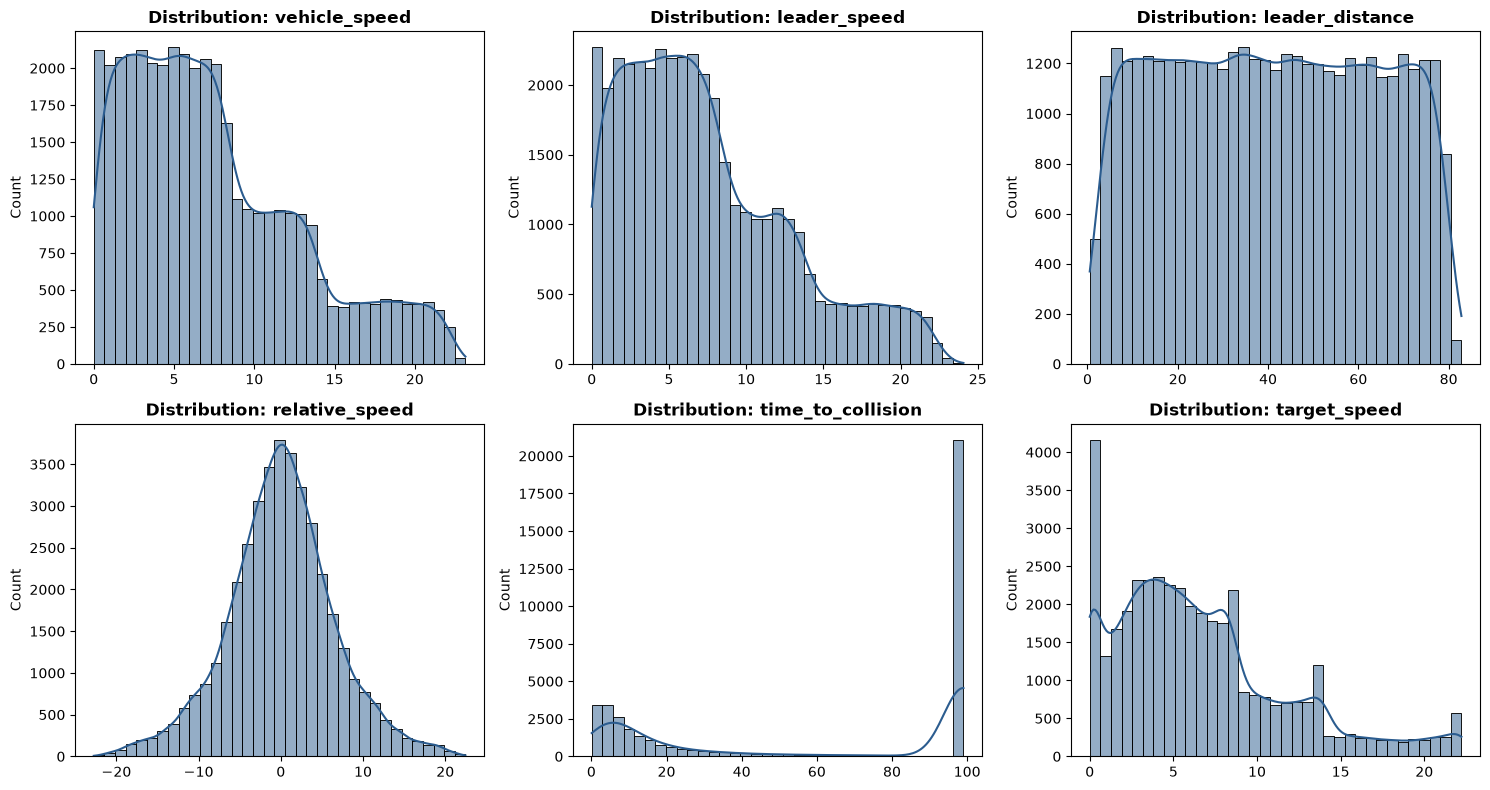

In [33]:
features = [
    "vehicle_speed", "leader_speed", "leader_distance", 
    "relative_speed", "time_to_collision", "target_speed"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=35, color="#2b5c8f")
    axes[i].set_title(f"Distribution: {col}", weight="bold")
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

Total Emergency Braking Samples: 3512


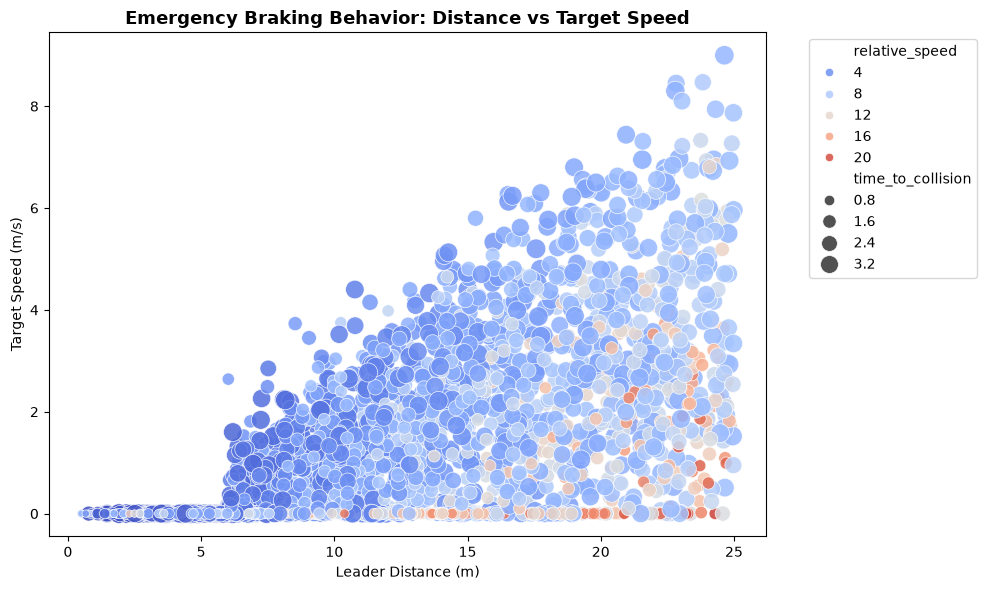

In [34]:
# Emergency braking zone filter (TTC < 4s & Distance < 25m)
emergency_mask = (df["time_to_collision"] < 4.0) & (df["leader_distance"] < 25.0)
emergency_samples = df[emergency_mask]

print(f"Total Emergency Braking Samples: {len(emergency_samples)}")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=emergency_samples,
    x="leader_distance",
    y="target_speed",
    hue="relative_speed",
    palette="coolwarm",
    size="time_to_collision",
    sizes=(25, 200),
    alpha=0.85
)
plt.title("Emergency Braking Behavior: Distance vs Target Speed", fontsize=13, weight="bold")
plt.xlabel("Leader Distance (m)")
plt.ylabel("Target Speed (m/s)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

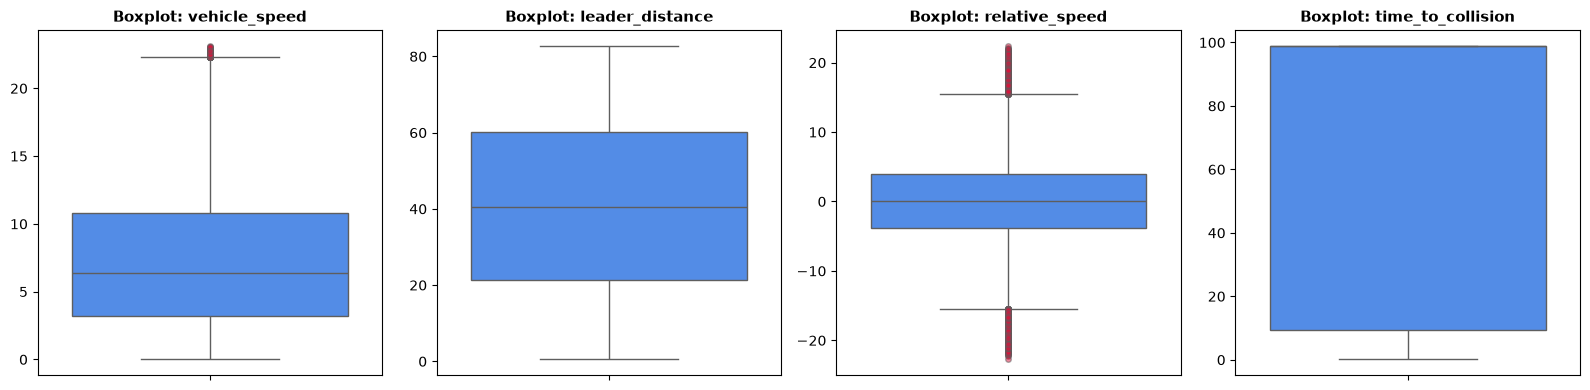

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
box_cols = ["vehicle_speed", "leader_distance", "relative_speed", "time_to_collision"]

for i, col in enumerate(box_cols):
    sns.boxplot(
        y=df[col], 
        ax=axes[i], 
        color="#3a86ff", 
        flierprops=dict(markerfacecolor='crimson', markersize=4, alpha=0.5)
    )
    axes[i].set_title(f"Boxplot: {col}", weight="bold", fontsize=11)
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()